In [8]:
import os
import random
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import pandas as pd

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

In [11]:
from datasets import load_dataset

dataset = load_dataset("geraldmc/plantvillage-full", revision="v0.1.0", split="train")
example = dataset[0]
example["image"]         # PIL Image, 256x256 RGB
example["class_label"]


/opt/python/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Generating train split: 100%|██████████| 54304/54304 [00:01<00:00, 30007.44 examples/s]


'Apple___Apple_scab'

In [12]:
from datasets import get_dataset_split_names
splits = get_dataset_split_names(
    "geraldmc/plantvillage-full",
    revision="v0.1.0"
)
splits
# So the 'train is not really anything to do with train or test'

['train']

In [13]:
dataset

Dataset({
    features: ['image', 'class_label', 'class_idx', 'host', 'disease', 'split', 'leaf_id', 'leaf_grouped'],
    num_rows: 54304
})

In [14]:
dataset = pd.DataFrame.from_dict(dataset)
dataset

,image,class_label,class_idx,host,disease,split,leaf_id,leaf_grouped
0,<PIL.JpegImagePlugin.JpegImageFile image mode=...,Apple___Apple_scab,0,Apple,Apple scab,test,Apple___Apple_scab::leaf_79,True
1,<PIL.JpegImagePlugin.JpegImageFile image mode=...,Apple___Apple_scab,0,Apple,Apple scab,test,Apple___Apple_scab::leaf_19,True
2,<PIL.JpegImagePlugin.JpegImageFile image mode=...,Apple___Apple_scab,0,Apple,Apple scab,test,Apple___Apple_scab::leaf_39,True
3,<PIL.JpegImagePlugin.JpegImageFile image mode=...,Apple___Apple_scab,0,Apple,Apple scab,train,Apple___Apple_scab::leaf_25,True
4,<PIL.JpegImagePlugin.JpegImageFile image mode=...,Apple___Apple_scab,0,Apple,Apple scab,train,Apple___Apple_scab::leaf_102,True
...,...,...,...,...,...,...,...,...
54299,<PIL.JpegImagePlugin.JpegImageFile image mode=...,Tomato___healthy,37,Tomato,healthy,test,Tomato___healthy::ff354b62-5981-43d1-8cfe-ac58...,False
54300,<PIL.JpegImagePlugin.JpegImageFile image mode=...,Tomato___healthy,37,Tomato,healthy,train,Tomato___healthy::leaf_229,True
54301,<PIL.JpegImagePlugin.JpegImageFile image mode=...,Tomato___healthy,37,Tomato,healthy,train,Tomato___healthy::leaf_57,True
54302,<PIL.JpegImagePlugin.JpegImageFile image mode=...,Tomato___healthy,37,Tomato,healthy,train,Tomato___healthy::leaf_221,True


In [15]:
train_data = dataset[dataset["split"] == "train"]
test_data = dataset[dataset["split"] == "test"]

In [16]:
train_data.head()

,image,class_label,class_idx,host,disease,split,leaf_id,leaf_grouped
3,<PIL.JpegImagePlugin.JpegImageFile image mode=...,Apple___Apple_scab,0,Apple,Apple scab,train,Apple___Apple_scab::leaf_25,True
4,<PIL.JpegImagePlugin.JpegImageFile image mode=...,Apple___Apple_scab,0,Apple,Apple scab,train,Apple___Apple_scab::leaf_102,True
5,<PIL.JpegImagePlugin.JpegImageFile image mode=...,Apple___Apple_scab,0,Apple,Apple scab,train,Apple___Apple_scab::leaf_28,True
6,<PIL.JpegImagePlugin.JpegImageFile image mode=...,Apple___Apple_scab,0,Apple,Apple scab,train,Apple___Apple_scab::leaf_105,True
7,<PIL.JpegImagePlugin.JpegImageFile image mode=...,Apple___Apple_scab,0,Apple,Apple scab,train,Apple___Apple_scab::leaf_82,True


In [17]:
train_data = train_data.drop('split', axis=1)
test_data = test_data.drop('split', axis=1)

In [18]:
len(train_data['class_label'].unique())

38

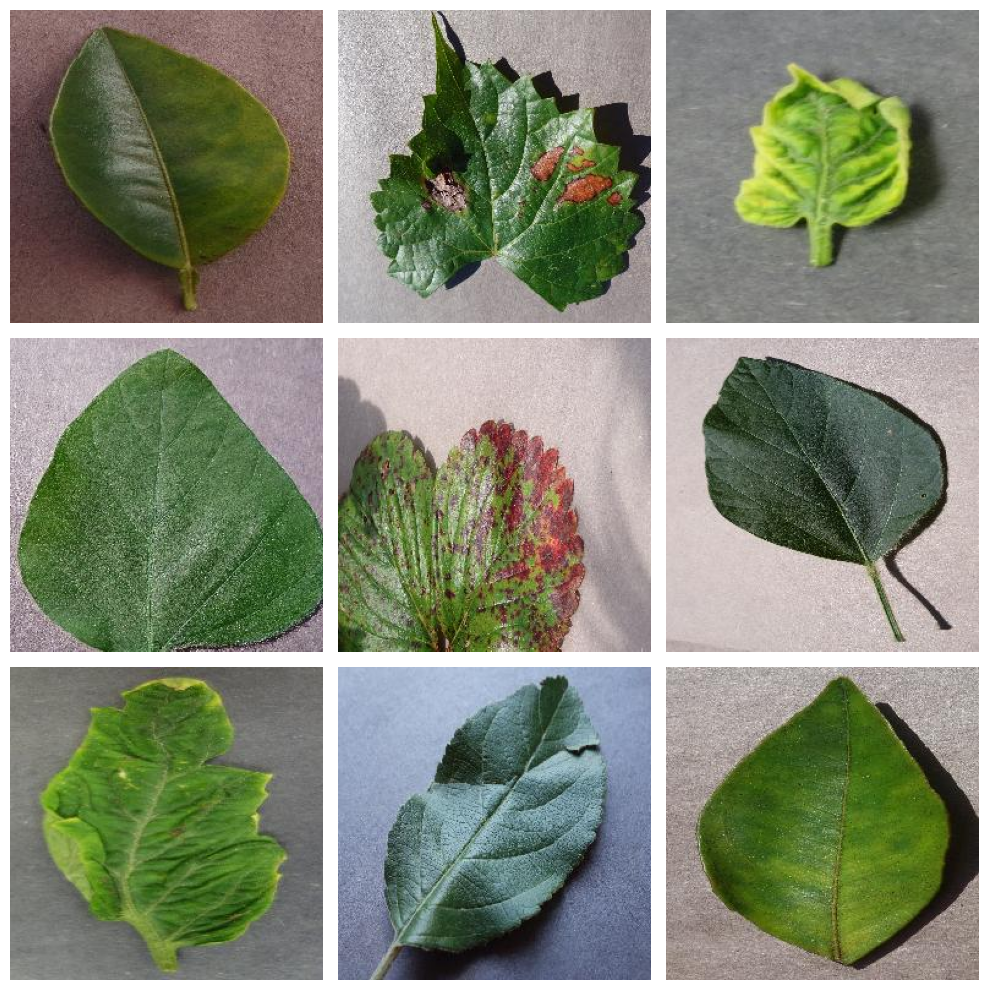

In [19]:
rows = 3
cols = 3

fig, axes = plt.subplots(rows, cols, figsize=(10, 10))

for row in range(rows):
  for col in range(cols):
    # Get a random image path from the dataframe
    sample = train_data.sample(n=1)["image"].iloc[0]
    #img = Image.open(sample) # the image is alr PIL itself!!!!
    axes[row, col].imshow(sample)
    axes[row, col].axis('off')
plt.tight_layout()
plt.show()

In [20]:
DEVICE = "cuda:0" if torch.cuda.is_available() else "cpu"

# limit CPU use so the lab remains responsive on laptops
if DEVICE == "cpu":
    torch.set_num_threads(min(4, os.cpu_count() or 1))
    torch.use_deterministic_algorithms(True)

In [21]:
sample = train_data["image"].iloc[0]

print(type(sample))
print(sample.size)
print(sample.mode)
print(sample.getpixel((0, 0))) #the pixel values are not normalized

<class 'PIL.JpegImagePlugin.JpegImageFile'>
(256, 256)
RGB
(234, 225, 242)


In [22]:
# sanity check: ToTensor scales pixels to [0, 1]
img_tensor = transforms.ToTensor()(sample)
print(img_tensor.min().item(), img_tensor.max().item())

0.0 1.0


In [23]:
print(type(train_data.iloc[0]["class_label"]))
print(repr(train_data.iloc[0]["class_label"])) #need to encode into integer!

<class 'str'>
'Apple___Apple_scab'


In [24]:
# ImageNet statistics; recompute on the train set as an optimization aid
# normally the model works just fine, not mandatory to use this normalization
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

# augmentation on train only
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

class PlantDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]
        image = row["image"].convert("RGB")
        if self.transform:
            image = self.transform(image)
        return image, torch.tensor(int(row["class_idx"]), dtype=torch.long)

# leaf never sit on both sides (a random split would leak and inflate val scores)
gss = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED)
tr_idx, val_idx = next(gss.split(train_data, groups=train_data["leaf_id"]))
fit_data = train_data.iloc[tr_idx]
val_data = train_data.iloc[val_idx]
print(len(fit_data), len(val_data), len(test_data))

g = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(PlantDataset(fit_data, train_transform), batch_size=32, shuffle=True, generator=g)
val_loader   = DataLoader(PlantDataset(val_data, eval_transform), batch_size=64, shuffle=False)
test_loader  = DataLoader(PlantDataset(test_data, eval_transform), batch_size=64, shuffle=False)

36828 6528 10948


In [25]:
def block(c_in, c_out):
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, 3, padding=1, bias=False),
        nn.BatchNorm2d(c_out),
        nn.ReLU(inplace=True),
        nn.Conv2d(c_out, c_out, 3, padding=1, bias=False),
        nn.BatchNorm2d(c_out),
        nn.ReLU(inplace=True),
        nn.MaxPool2d(2),
    )

class Cnn(nn.Module):
    def __init__(self, n_class):
        super().__init__()
        self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128), block(128, 256))
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Dropout(0.2),
            nn.Linear(256, n_class),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

In [26]:
N_EPOCHS = 20
model = Cnn(n_class=38).to(DEVICE)  

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer, max_lr=3e-3, epochs=N_EPOCHS, steps_per_epoch=len(train_loader)
)

In [27]:
def evaluate(loader):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            out = model(images)
            total_loss += criterion(out, labels).item() * labels.size(0)
            correct += (out.argmax(1) == labels).sum().item()
            total += labels.size(0)
    return total_loss / total, 100 * correct / total

history = {"train_loss": [], "val_loss": [], "val_acc": []}
for epoch in range(N_EPOCHS):
    model.train()
    running, n = 0.0, 0
    for images, labels in train_loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        loss = criterion(model(images), labels)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        scheduler.step()
        running += loss.item() * labels.size(0)
        n += labels.size(0)
    val_loss, val_acc = evaluate(val_loader)
    history["train_loss"].append(running / n)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)
    print(f"epoch {epoch+1:2d}/{N_EPOCHS}  train loss {running/n:.4f}  val loss {val_loss:.4f}  val acc {val_acc:.2f}%")

epoch  1/20  train loss 1.6419  val loss 0.9001  val acc 74.39%
epoch  2/20  train loss 0.7439  val loss 0.5991  val acc 80.44%
epoch  3/20  train loss 0.4614  val loss 0.5350  val acc 83.20%
epoch  4/20  train loss 0.3520  val loss 0.5478  val acc 81.83%
epoch  5/20  train loss 0.2898  val loss 0.7092  val acc 78.81%
epoch  6/20  train loss 0.2281  val loss 0.2221  val acc 93.24%
epoch  7/20  train loss 0.1932  val loss 0.1741  val acc 94.13%
epoch  8/20  train loss 0.1498  val loss 0.1635  val acc 95.04%
epoch  9/20  train loss 0.1256  val loss 0.1929  val acc 94.58%
epoch 10/20  train loss 0.1019  val loss 0.0760  val acc 97.50%
epoch 11/20  train loss 0.0900  val loss 0.1371  val acc 96.26%
epoch 12/20  train loss 0.0724  val loss 0.1041  val acc 96.98%
epoch 13/20  train loss 0.0552  val loss 0.0774  val acc 98.05%
epoch 14/20  train loss 0.0462  val loss 0.0382  val acc 98.88%
epoch 15/20  train loss 0.0338  val loss 0.0333  val acc 99.11%
epoch 16/20  train loss 0.0256  val loss

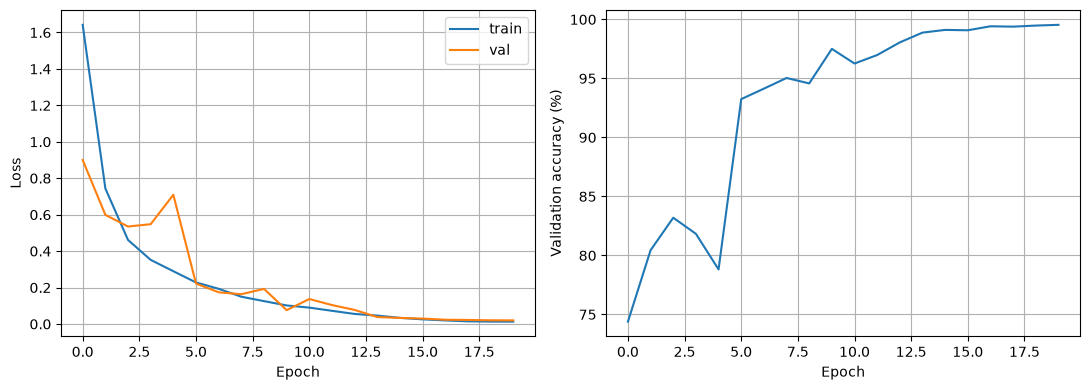

In [28]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(history["train_loss"], label="train")
ax[0].plot(history["val_loss"], label="val")
ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Loss"); ax[0].legend(); ax[0].grid(True)
ax[1].plot(history["val_acc"])
ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Validation accuracy (%)"); ax[1].grid(True)
plt.tight_layout(); plt.show()

In [29]:
test_loss, test_acc = evaluate(test_loader)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.2f}%")

Test Loss: 0.0133
Test Accuracy: 99.63%


In [30]:
model.eval()
preds, targets = [], []
with torch.no_grad():
    for images, labels in test_loader:
        preds += model(images.to(DEVICE)).argmax(1).cpu().tolist()
        targets += labels.tolist()

names = (dataset_names := test_data.drop_duplicates("class_idx").sort_values("class_idx")["class_label"].tolist())
print(classification_report(targets, preds, labels=sorted(set(targets)), target_names=names, digits=3))

                                                    precision    recall  f1-score   support

                                Apple___Apple_scab      1.000     0.992     0.996       123
                                 Apple___Black_rot      1.000     1.000     1.000       124
                          Apple___Cedar_apple_rust      1.000     1.000     1.000        55
                                   Apple___healthy      0.997     0.997     0.997       324
                               Blueberry___healthy      1.000     1.000     1.000       278
          Cherry_(including_sour)___Powdery_mildew      1.000     1.000     1.000       252
                 Cherry_(including_sour)___healthy      1.000     1.000     1.000       179
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot      0.980     0.951     0.966       103
                       Corn_(maize)___Common_rust_      1.000     1.000     1.000       238
               Corn_(maize)___Northern_Leaf_Blight      0.975     0.990     0.9

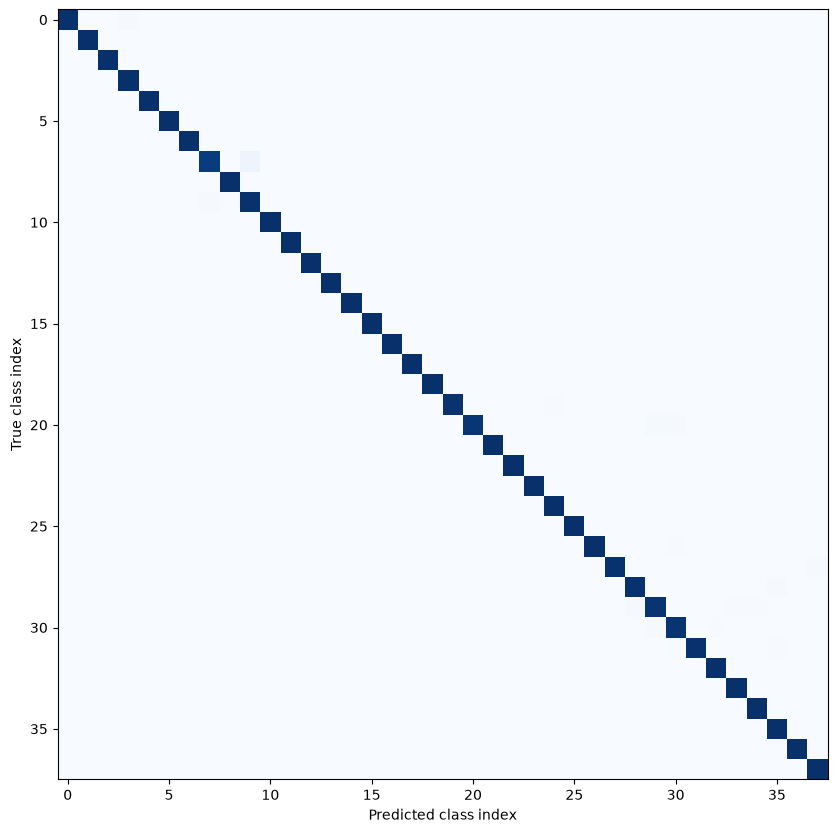

Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot  ->  Corn_(maize)___Northern_Leaf_Blight: 4.9%
Potato___Early_blight  ->  Tomato___Early_blight: 1.5%
Strawberry___healthy  ->  Tomato___healthy: 1.1%
Corn_(maize)___Northern_Leaf_Blight  ->  Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot: 1.0%
Potato___Early_blight  ->  Tomato___Late_blight: 1.0%


In [31]:
cm = confusion_matrix(targets, preds, normalize="true")
fig, ax = plt.subplots(figsize=(10, 10))
ax.imshow(cm, cmap="Blues")
ax.set_xlabel("Predicted class index"); ax.set_ylabel("True class index")
plt.show()

# most confused pairs
import numpy as np
off = cm.copy(); np.fill_diagonal(off, 0)
for i, j in zip(*np.unravel_index(np.argsort(off, axis=None)[::-1][:5], off.shape)):
    print(f"{names[i]}  ->  {names[j]}: {off[i, j]:.1%}")